# Interest rate swaps : pricing tests

Fixed / floating swaps on the EURIBOR 6M curve of 12/02/2025 (single-curve framework), with the products of
`Produits/rate_products.py` and the pricer of `Fixed_Income_Models/rate_pricing.py`:

$$
V^{payer} = \underbrace{\sum_j N_j \tau_j F_j P(0,t_j)}_{\text{floating leg}} - K \underbrace{\sum_i N_i \delta_i P(0,t_i)}_{\text{annuity}},
\qquad F_j = \frac{1}{\tau_j}\left(\frac{P(0,t_{j-1})}{P(0,t_j)} - 1\right).
$$

Fixed leg annual, floating leg semi-annual (EUR convention), year fractions without day count.

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..")))   # Projets : Fixed_Income_Models package
sys.path.append(os.path.abspath(".."))                       # Produits : rate_products.py, rates_market.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rates_market import eur_curve, illustrative_cap_vols, illustrative_swaption_vols
from rate_products import Swap, CapFloor, Swaption
from Fixed_Income_Models import (RatePricer, HullWhite, curve_risk, key_rate_risk, vega, bachelier, black,
                                 option_value, implied_vol)

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
curve = eur_curve()

## 1. Curve and par swap rates

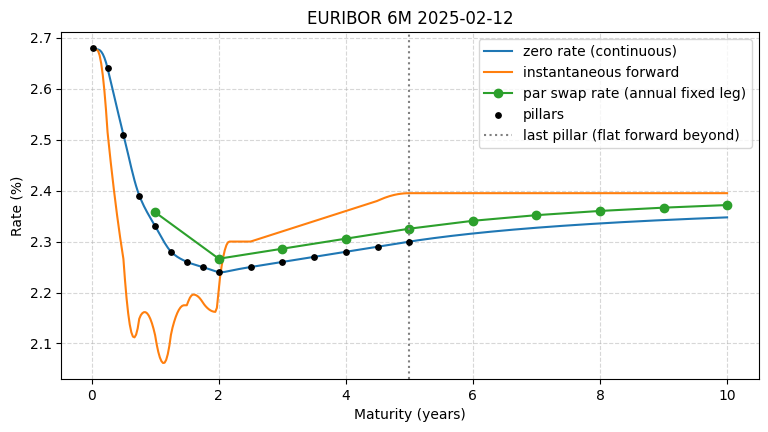

maturity (y),1,2,3,4,5,6,7,8,9,10
par swap rate (%),2.35736,2.26631,2.28597,2.30568,2.32531,2.34079,2.35184,2.36012,2.36655,2.37169


In [2]:
pricer = RatePricer(curve)
T = np.linspace(0.05, 10, 400)
maturities = np.arange(1, 11)
par_rates = [pricer.par_rate(Swap(m, 0.0)) for m in maturities]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(T, 100 * curve.zero_rate(T), label="zero rate (continuous)")
ax.plot(T, 100 * curve.instantaneous_forward(T), label="instantaneous forward")
ax.plot(maturities, 100 * np.array(par_rates), "o-", label="par swap rate (annual fixed leg)")
ax.scatter(curve.times, 100 * curve.zero_rates, color="black", zorder=5, s=15, label="pillars")
ax.axvline(curve.times[-1], color="grey", linestyle=":", label="last pillar (flat forward beyond)")
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Rate (%)"); ax.set_title(curve.name)
ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
plt.show()
pd.DataFrame({"par swap rate (%)": 100 * np.array(par_rates)}, index=pd.Index(maturities, name="maturity (y)")).T

## 2. A 5-year payer swap

Notional 1,000,000, fixed rate 2.50% (above the 5-year par rate: the payer swap has a negative value).

In [3]:
swap = Swap(5, 0.025, payer=True)
annuity, floating = pricer.swap_legs(swap)
print(swap)
print(f"Floating leg : {floating:,.2f} | Annuity : {annuity:,.2f} | Fixed leg : {swap.fixed_rate * annuity:,.2f}")
print(f"Value : {pricer.price(swap):,.2f} | Par rate : {100 * pricer.par_rate(swap):.4f}%")
pricer.swap_cashflows(swap)

Payer swap 5y(K=2.5000%, N=1,000,000, fixed 1/y, float 2/y, bullet)
Floating leg : 108,633.86 | Annuity : 4,671,806.66 | Fixed leg : 116,795.17
Value : -8,161.31 | Par rate : 2.3253%


,leg,start,end,notional,rate (%),amount,discount,PV
0,fixed,0,1,1e+06,2.5,"-25,000",0.976969,"-24,424.2"
1,fixed,1,2,1e+06,2.5,"-25,000",0.956189,"-23,904.7"
2,fixed,2,3,1e+06,2.5,"-25,000",0.934447,"-23,361.2"
3,fixed,3,4,1e+06,2.5,"-25,000",0.912835,"-22,820.9"
4,fixed,4,5,1e+06,2.5,"-25,000",0.891366,"-22,284.2"
5,float,0,0.5,1e+06,2.52582,"12,629.1",0.987528,"12,471.6"
6,float,0.5,1,1e+06,2.1616,"10,808",0.976969,"10,559.1"
7,float,1,1.5,1e+06,2.13128,"10,656.4",0.966668,"10,301.2"
8,float,1.5,2,1e+06,2.19192,"10,959.6",0.956189,"10,479.5"
9,float,2,2.5,1e+06,2.30316,"11,515.8",0.945303,"10,885.9"


## 3. Validation

- At the par rate the swap is worth 0; payer + receiver = 0.
- The par rate equals `YieldCurve.par_rate` (single-curve: $(1 - P(0,T)) / A$).
- Single-curve identity: the floating leg of a spot-starting bullet swap is worth $N (1 - P(0,T))$.

In [4]:
par = pricer.par_rate(swap)
checks = {"Value at the par rate": pricer.price(swap.with_rate(par)),
          "Payer + receiver": pricer.price(swap) + pricer.price(swap.reversed()),
          "Par rate - YieldCurve.par_rate (bp)": 1e4 * (par - curve.par_rate(5, 1)),
          "Floating leg - N (1 - P(0,5))": floating - swap.notional * (1 - curve.discount(5))}
pd.Series(checks, name="should be 0").to_frame()

,should be 0
Value at the par rate,0
Payer + receiver,0
Par rate - YieldCurve.par_rate (bp),-1.73472e-13
"Floating leg - N (1 - P(0,5))",-5.82077e-11


## 4. Forms of swaps

Spot and forward-starting, bullet and linearly amortizing, payer and receiver, and the effect of the fixed leg
frequency.

In [5]:
variants = {"Payer 5y": Swap(5, 0.025), "Receiver 5y": Swap(5, 0.025, payer=False),
            "Payer 2y x 3y (forward start)": Swap(5, 0.025, start=2), "Payer 5y x 5y (forward start)": Swap(10, 0.025, start=5),
            "Payer 5y amortizing": Swap(5, 0.025, amortization="linear"),
            "Payer 5y, semi-annual fixed": Swap(5, 0.025, fixed_frequency=2),
            "Payer 10y": Swap(10, 0.025)}
rows = {}
for name, s in variants.items():
    risk = curve_risk(pricer, s)
    rows[name] = {"par rate (%)": 100 * pricer.par_rate(s), "value": risk["value"], "annuity": pricer.swap_legs(s)[0],
                  "DV01 (per +1bp)": risk["DV01 (per +1bp)"], "convexity (per bp^2)": risk["convexity (per bp^2)"]}
pd.DataFrame(rows).T

,par rate (%),value,annuity,DV01 (per +1bp),convexity (per bp^2)
Payer 5y,2.32531,"-8,161.31",4.67181e+06,480.185,-0.235367
Receiver 5y,2.32531,"8,161.31",4.67181e+06,-480.185,0.235367
Payer 2y x 3y (forward start),2.36695,"-3,643.66",2.73865e+06,281.724,-0.195919
Payer 5y x 5y (forward start),2.42391,"-3,157.88",4.15022e+06,427.593,-0.635612
Payer 5y amortizing,2.11872,"-10,851.1",2.846e+06,270.351,-0.0928583
"Payer 5y, semi-annual fixed",2.31209,"-8,828.8",4.69851e+06,477.433,-0.233843
Payer 10y,2.37169,"-11,319.2",8.82203e+06,907.778,-0.870978


## 5. Risk

DV01 = value change for a +1bp parallel shift of the zero curve; key-rate sensitivities bump one pillar at a time.
For a payer swap the DV01 is positive and close to the annuity times 1bp.

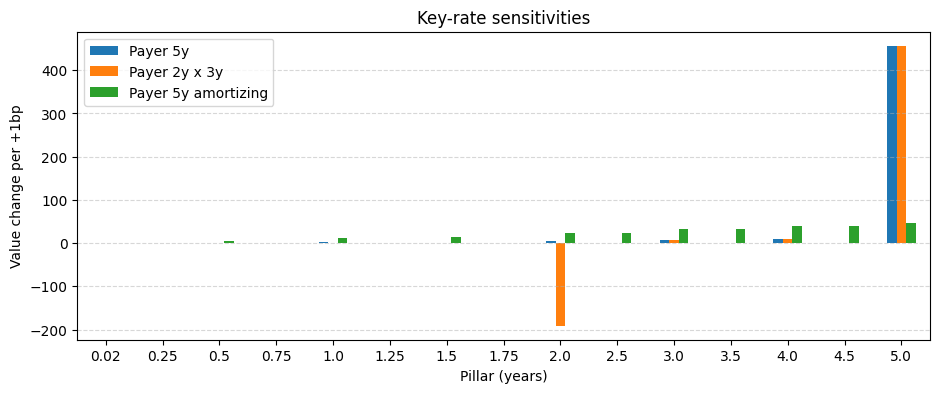

pillar (y),0.02,0.25,0.5,0.75,1,1.25,1.5,1.75,2,2.5,3,3.5,4,4.5,5
Payer 5y,0,0,-7.27596e-12,0,2.44242,0,0,0,4.78094,0,7.00836,7.27596e-12,9.12835,0,456.825
Payer 2y x 3y,0,0,0,0,0,0,0,0,-191.238,0,7.00836,0,9.12835,0,456.825
Payer 5y amortizing,0,0,4.93764,0,12.2121,0,14.5,0,22.9485,23.6326,32.2384,32.3268,40.1647,40.5937,46.7967


In [6]:
risk = pd.concat({name: key_rate_risk(pricer, s)["sensitivity (per +1bp)"] for name, s in
                  [("Payer 5y", variants["Payer 5y"]), ("Payer 2y x 3y", variants["Payer 2y x 3y (forward start)"]),
                   ("Payer 5y amortizing", variants["Payer 5y amortizing"])]}, axis=1)
ax = risk.plot.bar(figsize=(11, 4), rot=0)
ax.set_xlabel("Pillar (years)"); ax.set_ylabel("Value change per +1bp"); ax.set_title("Key-rate sensitivities")
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.show()
risk.T

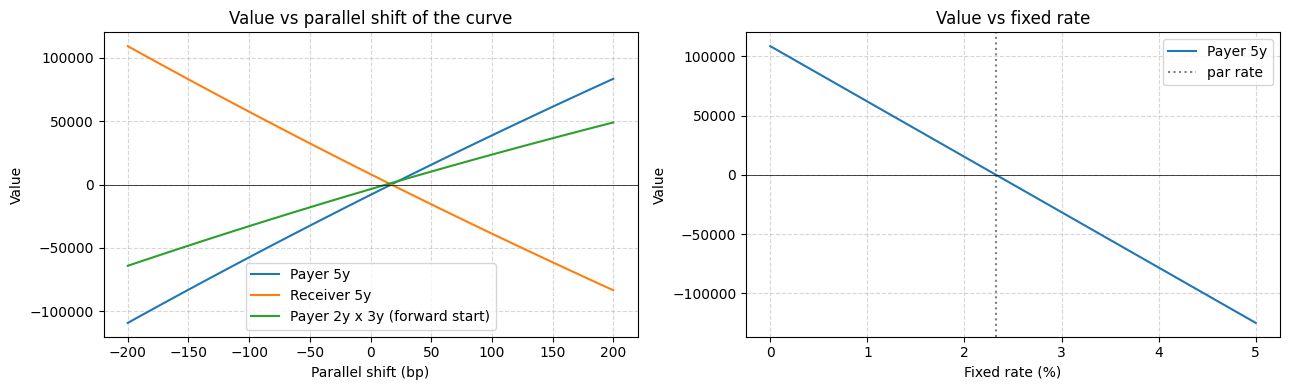

In [7]:
shifts = np.arange(-200, 201, 10)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in ["Payer 5y", "Receiver 5y", "Payer 2y x 3y (forward start)"]:
    axes[0].plot(shifts, [RatePricer(curve.shifted(b)).price(variants[name]) for b in shifts], label=name)
rates = np.linspace(0.0, 0.05, 51)
axes[1].plot(100 * rates, [pricer.price(swap.with_rate(k)) for k in rates], label="Payer 5y")
axes[1].axvline(100 * par, color="grey", linestyle=":", label="par rate")
axes[0].set_xlabel("Parallel shift (bp)"); axes[1].set_xlabel("Fixed rate (%)")
for ax, title in zip(axes, ["Value vs parallel shift of the curve", "Value vs fixed rate"]):
    ax.set_ylabel("Value"); ax.set_title(title); ax.axhline(0, color="black", linewidth=0.5)
    ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
plt.tight_layout(); plt.show()

## 6. Limitations

Single curve (no €STR discounting nor basis spreads), no day count, calendar or settlement lag, flat forward
extrapolation beyond 5 years (the 10-year swaps depend on it).